In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("LogFileParser").getOrCreate()


In [2]:
from google.colab import files

uploaded = files.upload()



Saving NASA_access_log_Jul95.gz to NASA_access_log_Jul95.gz


In [3]:
!ls

NASA_access_log_Jul95.gz  sample_data


In [4]:
rdd = spark.sparkContext.textFile("NASA_access_log_Jul95.gz")
rdd.take(5)

['199.72.81.55 - - [01/Jul/1995:00:00:01 -0400] "GET /history/apollo/ HTTP/1.0" 200 6245',
 'unicomp6.unicomp.net - - [01/Jul/1995:00:00:06 -0400] "GET /shuttle/countdown/ HTTP/1.0" 200 3985',
 '199.120.110.21 - - [01/Jul/1995:00:00:09 -0400] "GET /shuttle/missions/sts-73/mission-sts-73.html HTTP/1.0" 200 4085',
 'burger.letters.com - - [01/Jul/1995:00:00:11 -0400] "GET /shuttle/countdown/liftoff.html HTTP/1.0" 304 0',
 '199.120.110.21 - - [01/Jul/1995:00:00:11 -0400] "GET /shuttle/missions/sts-73/sts-73-patch-small.gif HTTP/1.0" 200 4179']

In [5]:
import re
from pyspark.sql import Row

#log_pattern = r'(\S+)  -- \[(.*?)\] "(.*?)" (\d{3}) (\S+)'
log_pattern = r'(\S+) - - \[(.*?)\] "(.*?)" (\d{3}) (\d+|-)'

In [6]:
import re

line = '199.72.81.55 - - [01/Jul/1995:00:00:01 -0400] "GET /history/apollo/ HTTP/1.0" 200 6245'

match = re.match(log_pattern, line)

if match:
  print(match.groups())
else :
  print("No Match")

('199.72.81.55', '01/Jul/1995:00:00:01 -0400', 'GET /history/apollo/ HTTP/1.0', '200', '6245')


In [7]:
def parse_log_file(line):
  match = re.match(log_pattern, line)   # apply regex

  if match:
    return Row(host = match.group(1),
               timestamp = match.group(2),
               request = match.group(3),
               status = match.group(4),
               size = match.group(5)
               )
  return None # Return None if no match

In [8]:
parsed_rdd = rdd.map(parse_log_file).filter(lambda x: x is not None)

In [9]:
parsed_rdd.take(4)

[Row(host='199.72.81.55', timestamp='01/Jul/1995:00:00:01 -0400', request='GET /history/apollo/ HTTP/1.0', status='200', size='6245'),
 Row(host='unicomp6.unicomp.net', timestamp='01/Jul/1995:00:00:06 -0400', request='GET /shuttle/countdown/ HTTP/1.0', status='200', size='3985'),
 Row(host='199.120.110.21', timestamp='01/Jul/1995:00:00:09 -0400', request='GET /shuttle/missions/sts-73/mission-sts-73.html HTTP/1.0', status='200', size='4085'),
 Row(host='burger.letters.com', timestamp='01/Jul/1995:00:00:11 -0400', request='GET /shuttle/countdown/liftoff.html HTTP/1.0', status='304', size='0')]

In [10]:
df = spark.createDataFrame(parsed_rdd)

In [11]:
df.show(10)

+--------------------+--------------------+--------------------+------+----+
|                host|           timestamp|             request|status|size|
+--------------------+--------------------+--------------------+------+----+
|        199.72.81.55|01/Jul/1995:00:00...|GET /history/apol...|   200|6245|
|unicomp6.unicomp.net|01/Jul/1995:00:00...|GET /shuttle/coun...|   200|3985|
|      199.120.110.21|01/Jul/1995:00:00...|GET /shuttle/miss...|   200|4085|
|  burger.letters.com|01/Jul/1995:00:00...|GET /shuttle/coun...|   304|   0|
|      199.120.110.21|01/Jul/1995:00:00...|GET /shuttle/miss...|   200|4179|
|  burger.letters.com|01/Jul/1995:00:00...|GET /images/NASA-...|   304|   0|
|  burger.letters.com|01/Jul/1995:00:00...|GET /shuttle/coun...|   200|   0|
|     205.212.115.106|01/Jul/1995:00:00...|GET /shuttle/coun...|   200|3985|
|         d104.aa.net|01/Jul/1995:00:00...|GET /shuttle/coun...|   200|3985|
|      129.94.144.152|01/Jul/1995:00:00...|      GET / HTTP/1.0|   200|7074|

In [12]:
df.count()

1891714

In [13]:
df.printSchema()

root
 |-- host: string (nullable = true)
 |-- timestamp: string (nullable = true)
 |-- request: string (nullable = true)
 |-- status: string (nullable = true)
 |-- size: string (nullable = true)



In [14]:
df.columns

['host', 'timestamp', 'request', 'status', 'size']

In [15]:
df.dtypes

[('host', 'string'),
 ('timestamp', 'string'),
 ('request', 'string'),
 ('status', 'string'),
 ('size', 'string')]

In [16]:
df.show()

+--------------------+--------------------+--------------------+------+-----+
|                host|           timestamp|             request|status| size|
+--------------------+--------------------+--------------------+------+-----+
|        199.72.81.55|01/Jul/1995:00:00...|GET /history/apol...|   200| 6245|
|unicomp6.unicomp.net|01/Jul/1995:00:00...|GET /shuttle/coun...|   200| 3985|
|      199.120.110.21|01/Jul/1995:00:00...|GET /shuttle/miss...|   200| 4085|
|  burger.letters.com|01/Jul/1995:00:00...|GET /shuttle/coun...|   304|    0|
|      199.120.110.21|01/Jul/1995:00:00...|GET /shuttle/miss...|   200| 4179|
|  burger.letters.com|01/Jul/1995:00:00...|GET /images/NASA-...|   304|    0|
|  burger.letters.com|01/Jul/1995:00:00...|GET /shuttle/coun...|   200|    0|
|     205.212.115.106|01/Jul/1995:00:00...|GET /shuttle/coun...|   200| 3985|
|         d104.aa.net|01/Jul/1995:00:00...|GET /shuttle/coun...|   200| 3985|
|      129.94.144.152|01/Jul/1995:00:00...|      GET / HTTP/1.0|

In [17]:
df.show()

+--------------------+--------------------+--------------------+------+-----+
|                host|           timestamp|             request|status| size|
+--------------------+--------------------+--------------------+------+-----+
|        199.72.81.55|01/Jul/1995:00:00...|GET /history/apol...|   200| 6245|
|unicomp6.unicomp.net|01/Jul/1995:00:00...|GET /shuttle/coun...|   200| 3985|
|      199.120.110.21|01/Jul/1995:00:00...|GET /shuttle/miss...|   200| 4085|
|  burger.letters.com|01/Jul/1995:00:00...|GET /shuttle/coun...|   304|    0|
|      199.120.110.21|01/Jul/1995:00:00...|GET /shuttle/miss...|   200| 4179|
|  burger.letters.com|01/Jul/1995:00:00...|GET /images/NASA-...|   304|    0|
|  burger.letters.com|01/Jul/1995:00:00...|GET /shuttle/coun...|   200|    0|
|     205.212.115.106|01/Jul/1995:00:00...|GET /shuttle/coun...|   200| 3985|
|         d104.aa.net|01/Jul/1995:00:00...|GET /shuttle/coun...|   200| 3985|
|      129.94.144.152|01/Jul/1995:00:00...|      GET / HTTP/1.0|

TOP 10 HOST (Who access most)


In [18]:
df.groupBy("host").count().orderBy("Count", ascending=False).show()

+--------------------+-----+
|                host|count|
+--------------------+-----+
|piweba3y.prodigy.com|17572|
|piweba4y.prodigy.com|11591|
|piweba1y.prodigy.com| 9868|
|  alyssa.prodigy.com| 7852|
| siltb10.orl.mmc.com| 7573|
|piweba2y.prodigy.com| 5922|
|  edams.ksc.nasa.gov| 5434|
|        163.206.89.4| 4906|
|         news.ti.com| 4863|
|disarray.demon.co.uk| 4353|
|www-a2.proxy.aol.com| 4179|
|www-d1.proxy.aol.com| 4158|
|  vagrant.vf.mmc.com| 4146|
|       198.133.29.18| 4136|
|   poppy.hensa.ac.uk| 4117|
|www-d4.proxy.aol.com| 3977|
|    webgate1.mot.com| 3843|
|www-b3.proxy.aol.com| 3755|
|  e659229.boeing.com| 3737|
|www-b2.proxy.aol.com| 3732|
+--------------------+-----+
only showing top 20 rows



In [19]:
from os import truncate
df.select('request').show(truncate = False)

+--------------------------------------------------------------+
|request                                                       |
+--------------------------------------------------------------+
|GET /history/apollo/ HTTP/1.0                                 |
|GET /shuttle/countdown/ HTTP/1.0                              |
|GET /shuttle/missions/sts-73/mission-sts-73.html HTTP/1.0     |
|GET /shuttle/countdown/liftoff.html HTTP/1.0                  |
|GET /shuttle/missions/sts-73/sts-73-patch-small.gif HTTP/1.0  |
|GET /images/NASA-logosmall.gif HTTP/1.0                       |
|GET /shuttle/countdown/video/livevideo.gif HTTP/1.0           |
|GET /shuttle/countdown/countdown.html HTTP/1.0                |
|GET /shuttle/countdown/ HTTP/1.0                              |
|GET / HTTP/1.0                                                |
|GET /shuttle/countdown/count.gif HTTP/1.0                     |
|GET /images/NASA-logosmall.gif HTTP/1.0                       |
|GET /images/KSC-logosmal

In [27]:
from pyspark.sql.functions import regexp_extract




✅ Step 2: Extract URL from request

In [28]:
from pyspark.sql.functions import regexp_extract

# Extract URL part from the "request" column
df = df.withColumn("endpoint", regexp_extract("request", r'^\S+\s+(\S+)\s+', 1))

top_endpoints = df.groupBy("endpoint").count()

✅ Step 3: Count hits per URL

In [ ]:
top_endpoints = df.groupBy("endpoint").count().show()

✅ Step 4: Sort in descending order

In [29]:
top_endpoints = top_endpoints.orderBy("count", ascending=False)
top_endpoints.show()

+--------------------+------+
|            endpoint| count|
+--------------------+------+
|/images/NASA-logo...|111144|
|/images/KSC-logos...| 89530|
|/images/MOSAIC-lo...| 60300|
|/images/USA-logos...| 59845|
|/images/WORLD-log...| 59325|
|/images/ksclogo-m...| 58616|
|/images/launch-lo...| 40841|
| /shuttle/countdown/| 40251|
|           /ksc.html| 40072|
|/images/ksclogosm...| 33555|
|                   /| 32749|
|/history/apollo/i...| 31052|
|/shuttle/missions...| 24834|
|  /htbin/cdt_main.pl| 22601|
|/shuttle/countdow...| 22189|
|/shuttle/countdow...| 21981|
|/shuttle/countdow...| 20921|
|/images/launchmed...| 20788|
|/shuttle/missions...| 19832|
|/shuttle/missions...| 18135|
+--------------------+------+
only showing top 20 rows



✅ Step 5: Show top 10 most popular pages

In [30]:
top_endpoints.show(10, truncate=False)


+----------------------------+------+
|endpoint                    |count |
+----------------------------+------+
|/images/NASA-logosmall.gif  |111144|
|/images/KSC-logosmall.gif   |89530 |
|/images/MOSAIC-logosmall.gif|60300 |
|/images/USA-logosmall.gif   |59845 |
|/images/WORLD-logosmall.gif |59325 |
|/images/ksclogo-medium.gif  |58616 |
|/images/launch-logo.gif     |40841 |
|/shuttle/countdown/         |40251 |
|/ksc.html                   |40072 |
|/images/ksclogosmall.gif    |33555 |
+----------------------------+------+
only showing top 10 rows



5️⃣ Error Analysis (HTTP Status Codes)

In [31]:
df.groupBy("Status").count().orderBy("count",ascending=False).show()

+------+-------+
|Status|  count|
+------+-------+
|   200|1701534|
|   304| 132627|
|   302|  46573|
|   404|  10845|
|   500|     62|
|   403|     54|
|   501|     14|
|   400|      5|
+------+-------+



In [32]:
df.filter(df.status == 404).groupBy("Status").count().orderBy("count",ascending=False).show()

+------+-----+
|Status|count|
+------+-----+
|   404|10845|
+------+-----+



6️⃣ Requests Over Time (Hourly or Daily Trends)

In [39]:
from pyspark.sql.functions import to_timestamp,date_format, regexp_replace

df= df.withColumn("datetime",to_timestamp(regexp_replace("timestamp", "-\\d{4}", ""), "dd/MMM/yyyy:HH:mm:ss"))
df = df.withColumn("hour",date_format("datetime","HH"))
df = df.withColumn("date",date_format("datetime","dd"))

df.groupBy("date").count().orderBy("date",ascending=False).show()

+----+------+
|date| count|
+----+------+
|  28| 27121|
|  27| 61680|
|  26| 58849|
|  25| 62699|
|  24| 64259|
|  23| 39199|
|  22| 35267|
|  21| 64629|
|  20| 66593|
|  19| 72738|
|  18| 64282|
|  17| 74981|
|  16| 47854|
|  15| 45532|
|  14| 84103|
|  13|134203|
|  12| 92536|
|  11| 80407|
|  10| 72860|
|  09| 35272|
+----+------+
only showing top 20 rows



In [38]:
spark.conf.set("spark.sql.legacy.timeParserPolicy", "LEGACY")

🌍 8️⃣ Detect Bots / Crawlers

In [40]:
df.show(10)

+--------------------+--------------------+--------------------+------+----+--------------------+-------------------+----+----+
|                host|           timestamp|             request|status|size|            endpoint|           datetime|hour|date|
+--------------------+--------------------+--------------------+------+----+--------------------+-------------------+----+----+
|        199.72.81.55|01/Jul/1995:00:00...|GET /history/apol...|   200|6245|    /history/apollo/|1995-07-01 00:00:01|  00|  01|
|unicomp6.unicomp.net|01/Jul/1995:00:00...|GET /shuttle/coun...|   200|3985| /shuttle/countdown/|1995-07-01 00:00:06|  00|  01|
|      199.120.110.21|01/Jul/1995:00:00...|GET /shuttle/miss...|   200|4085|/shuttle/missions...|1995-07-01 00:00:09|  00|  01|
|  burger.letters.com|01/Jul/1995:00:00...|GET /shuttle/coun...|   304|   0|/shuttle/countdow...|1995-07-01 00:00:11|  00|  01|
|      199.120.110.21|01/Jul/1995:00:00...|GET /shuttle/miss...|   200|4179|/shuttle/missions...|1995-07

In [41]:
df.groupBy("host").count().filter("count > 1000").orderBy("count",ascending = False).show(10)

+--------------------+-----+
|                host|count|
+--------------------+-----+
|piweba3y.prodigy.com|17572|
|piweba4y.prodigy.com|11591|
|piweba1y.prodigy.com| 9868|
|  alyssa.prodigy.com| 7852|
| siltb10.orl.mmc.com| 7573|
|piweba2y.prodigy.com| 5922|
|  edams.ksc.nasa.gov| 5434|
|        163.206.89.4| 4906|
|         news.ti.com| 4863|
|disarray.demon.co.uk| 4353|
+--------------------+-----+
only showing top 10 rows



9️⃣ Combine Insights — Top Pages with Most Errors

In [42]:
df.filter(df.status == 404).groupBy("endpoint").count().orderBy("count",ascending=False).show()

+--------------------+-----+
|            endpoint|count|
+--------------------+-----+
|/pub/winvn/readme...|  667|
|/pub/winvn/releas...|  547|
|/history/apollo/a...|  286|
|/shuttle/resource...|  230|
|/history/apollo/a...|  230|
|/history/apollo/p...|  215|
|/://spacelink.msf...|  215|
|/images/crawlerwa...|  214|
|/history/apollo/s...|  183|
|/shuttle/resource...|  180|
|/shuttle/missions...|  175|
|/shuttle/missions...|  168|
|/elv/DELTA/uncons...|  163|
|/history/apollo/p...|  140|
|/shuttle/missions...|  107|
|/shuttle/resource...|   92|
|/procurement/proc...|   86|
|/history/apollo-1...|   73|
|/history/apollo/p...|   71|
|                    |   69|
+--------------------+-----+
only showing top 20 rows



📊 10️⃣ Visualize

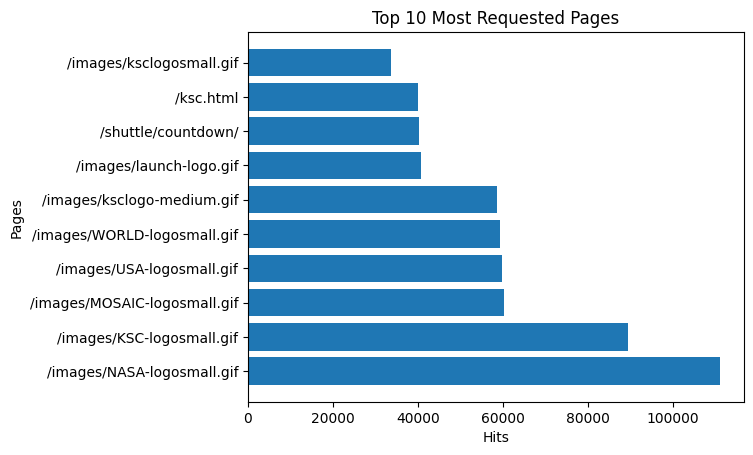

In [43]:
import matplotlib.pyplot as plt

top_pages = df.groupBy("endpoint").count().orderBy("count", ascending=False).limit(10).toPandas()
plt.barh(top_pages['endpoint'], top_pages['count'])
plt.xlabel("Hits")
plt.ylabel("Pages")
plt.title("Top 10 Most Requested Pages")
plt.show()
